<a href="https://colab.research.google.com/github/Lucas-O-S/N1_IA_VisaoComputacional/blob/main/CNN_Malaria_Grupo_executado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação de células com malária usando uma CNN
**Conjunto de dados:** *Cell Images for Detecting Malaria* (NIH / Kaggle), 2 classes: **Parasitized** e **Uninfected**

**Grupo:** _(nomes e RA)_

**Roteiro do notebook**
0. Contexto: a malária e o que aparece nas lâminas
1. Configuração e semente fixa
2. Download e descrição do conjunto
3. Análise exploratória (amostras, distribuição, resolução, problemas do conjunto)
4. Pré-processamento (redimensionamento) e divisão treino/validação/teste sem vazamento
5. Arquitetura da CNN baseline, construída camada por camada (com a teoria de cada camada)
6. Experimentos: baseline + 6 experimentos, **um fator por vez**, com tabela
7. Comparação com transfer learning (somente referência)
8. Avaliação final no conjunto de teste (usado **uma única vez**), com explicação das métricas
9. Análise de erros e Grad-CAM
10. Conclusão
11. Log de uso de IA

> **Como estudar por este notebook:** cada etapa tem um bloco **📘 Teoria** (o conceito) e um bloco **🔧 O que o código faz** (o passo a passo). Os comentários `#` dentro do código explicam linha por linha.
>
> **Ambiente:** use *Ambiente de execução → Alterar o tipo de ambiente → GPU T4*. Na CPU também roda, mas fica bem mais lento (cerca de 1h20 contra poucos minutos na GPU).

> **Versão executada:** esta cópia contém as saídas reais de uma execução completa (CPU, 7 treinos, ~1h20) com o arquivo `archive.zip` do Kaggle. As duas únicas diferenças em relação à versão para o Colab são `DATA_DIR_MANUAL` (pasta local) e `RODAR_TRANSFER = False`. Para o relatório oficial, rodem `CNN_Malaria_Grupo.ipynb` no Colab.

## 0. Contexto: a malária e o que aparece nas lâminas

### 📘 A doença
A **malária** é causada por protozoários do gênero ***Plasmodium***, transmitidos pela picada da fêmea do mosquito ***Anopheles***. As espécies que infectam humanos são *P. falciparum*, *P. vivax*, *P. malariae*, *P. ovale* e *P. knowlesi*. O ***P. falciparum*** causa as formas mais graves; é a espécie das lâminas deste conjunto.

### 📘 Ciclo de vida no ser humano
1. **Mosquito pica e injeta esporozoítos**, que vão para o **fígado** (fase hepática, sem sintomas).
2. No fígado, eles se multiplicam e liberam **merozoítos** no sangue.
3. **Ciclo eritrocítico** (é o que vemos na lâmina): o merozoíto invade a **hemácia** e passa por fases:
   - **Anel (trofozoíto jovem):** um pontinho de cromatina (núcleo) com um aro fino de citoplasma, parecido com um anel de sinete.
   - **Trofozoíto maduro:** o parasita cresce, fica mais denso e acumula pigmento (hemozoína).
   - **Esquizonte:** o núcleo se divide em vários merozoítos.
   - **Ruptura da hemácia:** libera novos merozoítos, que infectam outras hemácias. A ruptura sincronizada causa os **picos de febre**.
4. Alguns parasitas viram **gametócitos** (formas sexuadas). No *P. falciparum* eles têm **forma de banana/crescente** e são o que o mosquito ingere para continuar o ciclo.

### 📘 Quais fases aparecem nestas imagens?
No *P. falciparum*, as hemácias com trofozoítos maduros e esquizontes **grudam na parede dos vasos pequenos** (sequestro/citoaderência) e quase não circulam. Por isso, no **sangue periférico** (a gota coletada para a lâmina) aparecem principalmente:
- **anéis (trofozoítos jovens)**, muitas vezes com **dois pontos de cromatina** ou **mais de um anel por hemácia**;
- **formas "accolé" (appliqué)**: o anel fica **colado na borda da hemácia**;
- às vezes **gametócitos em crescente**.

Então, nas imagens *Parasitized*, a "mancha roxa" que a rede precisa achar é quase sempre um **anel pequeno**, que pode estar **no meio ou na borda** da célula. Isso ajuda a entender o Grad-CAM e os erros mais adiante.

### 📘 A lâmina e a coloração
- **Esfregaço fino:** uma camada única de células espalhada na lâmina; permite ver cada hemácia e identificar a espécie. (O **esfregaço espesso** concentra mais sangue e serve para triagem.)
- **Coloração de Giemsa:** a hemácia fica **rosa/lilás**, a **cromatina do parasita fica roxo-avermelhada** e o citoplasma do parasita fica **azulado**. Por isso **a cor é uma informação importante** para a rede, e mantemos as imagens em RGB.
- O diagnóstico manual é **lento e cansativo**: o microscopista conta milhares de células por lâmina. Um classificador automático ajudaria na triagem.

### 📘 Origem deste conjunto
Lâminas de **150 pacientes com *P. falciparum* e 50 pessoas saudáveis**, coletadas no Chittagong Medical College Hospital (Bangladesh) e fotografadas com a câmera de um **celular acoplado ao microscópio**. As células foram recortadas automaticamente de cada foto e rotuladas por um especialista da Mahidol-Oxford Tropical Medicine Research Unit (Tailândia). Uma versão revisada posterior (IEEE DataPort) relata que **uma parte relevante das imagens estava com o rótulo errado**, o que vamos ver na análise de erros.

## 1. Configuração e semente fixa

### 📘 Teoria: por que fixar a semente?
Treinar uma rede envolve **sorteios**: a inicialização dos pesos, a ordem das imagens em cada época, a divisão dos dados e o data augmentation. Fixando a **semente** (`SEED = 42`), esses sorteios se repetem, e o notebook dá **o mesmo resultado** a cada execução, que é o requisito de **reprodutibilidade**. (Na GPU podem sobrar diferenças mínimas, por causa da ordem das somas em paralelo.)

### 📘 Por que redimensionar para 64×64?
As imagens originais têm ~130×130 px. Uma imagem 64×64 tem **4× menos pixels**: menos memória, treino mais rápido e cabe no Colab gratuito. O parasita continua visível nesse tamanho.

In [ ]:
# --- Bibliotecas ---
import os, glob, re, time, hashlib, random, zipfile, shutil   # utilitários de arquivos, tempo e hash
import numpy as np                  # vetores/matrizes (as imagens viram arrays numpy)
import pandas as pd                 # tabelas (DataFrame)
import matplotlib.pyplot as plt     # gráficos
from PIL import Image               # abrir e redimensionar imagens
from tqdm.auto import tqdm          # barra de progresso

import tensorflow as tf             # framework de deep learning
import keras                        # API de alto nível para montar redes
from keras import layers            # camadas: Conv2D, MaxPooling2D, Dense...

from sklearn.model_selection import StratifiedGroupKFold          # divisão por grupos (lâminas)
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score, roc_auc_score)

# --- Reprodutibilidade ---
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
keras.utils.set_random_seed(SEED)   # fixa random, numpy e tensorflow de uma vez

# --- Hiperparâmetros gerais ---
IMG_SIZE = 64      # imagens redimensionadas para 64x64 (economiza memória e tempo de CPU/GPU)
BATCH    = 64      # quantas imagens a rede vê antes de cada atualização dos pesos
EPOCHS   = 20      # máximo de épocas por experimento (igual para todos); 1 época = ver o treino inteiro 1 vez
CLASSES  = ['Uninfected', 'Parasitized']   # índice 0 = não infectada, 1 = parasitada (classe positiva)
RODAR_TRANSFER = False   # nesta execução: pesos ImageNet indisponíveis no ambiente; rodar no Colab

# Pasta onde todas as figuras e tabelas são salvas (para usar nos slides)
FIG_DIR = 'figs'
os.makedirs(FIG_DIR, exist_ok=True)
def salvar(nome):
    plt.savefig(os.path.join(FIG_DIR, nome), dpi=150, bbox_inches='tight')

print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'nenhuma (rodando na CPU)')

I0000 00:00:1793356829.457072     268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793356842.823391     268 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793356849.931225     268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1
GPU: nenhuma (rodando na CPU)


## 2. Download e descrição do conjunto

São **27.558 imagens de hemácias isoladas** (cada imagem é uma única célula recortada da foto da lâmina):

| Classe | O que se vê | Rótulo no código |
|---|---|---|
| **Parasitized** | hemácia com o parasita: mancha roxa (anel) no interior ou na borda | `1` (classe positiva) |
| **Uninfected** | hemácia sem parasita: coloração uniforme, às vezes com artefatos | `0` |

O nome de cada arquivo indica a **lâmina/paciente** de origem (ex.: `C33P1thinF_IMG_..._cell_179.png`: lâmina C33, paciente P1, esfregaço fino *thin*). Isso é usado mais adiante para evitar vazamento.

### 🔧 O que o código faz
Baixa o conjunto com o `kagglehub` (dataset público). Se falhar, tenta o link oficial do NIH. Também dá para apontar `DATA_DIR_MANUAL` para uma pasta já extraída (por exemplo, no Google Drive).

In [ ]:
DATA_DIR_MANUAL = '/home/claude/res/data/archive'   # nesta execução: pasta com o zip enviado

def baixar_dataset():
    # 1ª opção: pasta informada manualmente
    if DATA_DIR_MANUAL:
        return DATA_DIR_MANUAL, 'pasta manual'
    # 2ª opção: Kaggle (dataset público, em geral não pede login)
    try:
        import kagglehub
        return kagglehub.dataset_download('iarunava/cell-images-for-detecting-malaria'), 'Kaggle (kagglehub)'
    except Exception as e:
        print('kagglehub falhou:', e, '\nTentando o link do NIH...')
    # 3ª opção: zip original do NIH
    url = 'https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip'
    if not os.path.exists('cell_images.zip'):
        tf.keras.utils.get_file(os.path.abspath('cell_images.zip'), url)
    with zipfile.ZipFile('cell_images.zip') as z:
        z.extractall('malaria_nih')
    return 'malaria_nih', 'NIH'

DATA_DIR, FONTE = baixar_dataset()
print('Fonte:', FONTE, '| Pasta:', DATA_DIR)

Fonte: pasta manual | Pasta: /home/claude/res/data/archive


### 🔧 Montando a tabela de imagens
Percorremos todas as pastas atrás de arquivos `.png`. A **classe** é o nome da pasta (`Parasitized` ou `Uninfected`). Algumas versões do Kaggle trazem a pasta `cell_images` **repetida dentro dela mesma**; por segurança removemos cópias pelo nome do arquivo (na nossa execução não havia cópias: 27.558 arquivos → 27.558 únicos).

A função `lamina()` pega o trecho do nome antes de `_IMG`, que identifica a lâmina/paciente.

In [ ]:
# Lista todos os .png, em qualquer subpasta (recursive=True)
todos = sorted(glob.glob(os.path.join(DATA_DIR, '**', '*.png'), recursive=True))
registros = {}
for p in todos:
    classe = os.path.basename(os.path.dirname(p))      # nome da pasta = classe
    if classe in CLASSES:
        registros.setdefault((classe, os.path.basename(p)), p)   # guarda só a 1ª cópia de cada nome

def lamina(nome):
    # parte do nome antes de '_IMG' = identificador da lâmina/paciente
    m = re.match(r'^(.*?)_IMG', nome)
    return (m.group(1) if m else nome).lower().replace('_', '')

# Uma linha por imagem: caminho, nome, classe, rótulo numérico e lâmina
df = pd.DataFrame([{'arquivo': p, 'nome': n, 'classe': c, 'label': CLASSES.index(c), 'lamina': lamina(n)}
                   for (c, n), p in registros.items()])
assert len(df) > 0, f'Nenhuma imagem encontrada em {DATA_DIR}: confira o download ou DATA_DIR_MANUAL'
print(f'Arquivos .png encontrados: {len(todos)}  ->  imagens únicas por nome: {len(df)}')
df.head()

Arquivos .png encontrados: 27558  ->  imagens únicas por nome: 27558


,arquivo,nome,classe,label,lamina
0,/home/claude/res/data/archive/cell_images/Para...,C100P61ThinF_IMG_20150918_144104_cell_162.png,Parasitized,1,c100p61thinf
1,/home/claude/res/data/archive/cell_images/Para...,C100P61ThinF_IMG_20150918_144104_cell_163.png,Parasitized,1,c100p61thinf
2,/home/claude/res/data/archive/cell_images/Para...,C100P61ThinF_IMG_20150918_144104_cell_164.png,Parasitized,1,c100p61thinf
3,/home/claude/res/data/archive/cell_images/Para...,C100P61ThinF_IMG_20150918_144104_cell_165.png,Parasitized,1,c100p61thinf
4,/home/claude/res/data/archive/cell_images/Para...,C100P61ThinF_IMG_20150918_144104_cell_166.png,Parasitized,1,c100p61thinf


## 3. Análise exploratória (EDA)

### 📘 Teoria: para que serve a EDA?
Antes de treinar, olhamos os dados para descobrir **problemas que estragariam o modelo ou a avaliação**:
- **Desbalanceamento:** se uma classe for muito maior, a rede pode "chutar" sempre a maior e ainda ter acurácia alta.
- **Tamanhos diferentes:** a CNN precisa de entradas do mesmo tamanho.
- **Duplicatas:** a mesma imagem em treino e teste infla o resultado.
- **Vieses:** características que se correlacionam com a classe sem ter relação com a doença (ex.: lâmina, cor da coloração).

### 3.1 Amostras por classe e distribuição

classe
Uninfected     13779
Parasitized    13779
Name: count, dtype: int64 

classe
Uninfected     50.0 %
Parasitized    50.0 %
Name: count, dtype: str


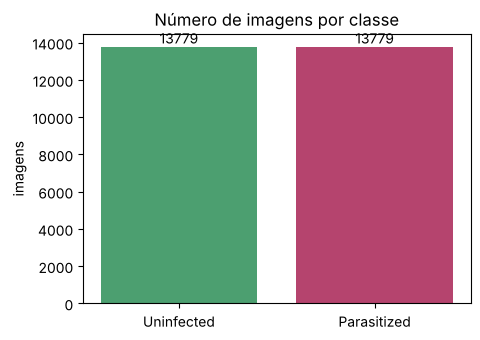

In [ ]:
# Conta quantas imagens há em cada classe
contagem = df['classe'].value_counts().reindex(CLASSES)
print(contagem, '\n')
print((contagem / contagem.sum() * 100).round(2).astype(str) + ' %')

# Gráfico de barras com a contagem
plt.figure(figsize=(5, 3.5))
bars = plt.bar(contagem.index, contagem.values, color=['#4C9F70', '#B5446E'])
plt.bar_label(bars)
plt.title('Número de imagens por classe'); plt.ylabel('imagens')
salvar('eda_distribuicao_classes.png'); plt.show()

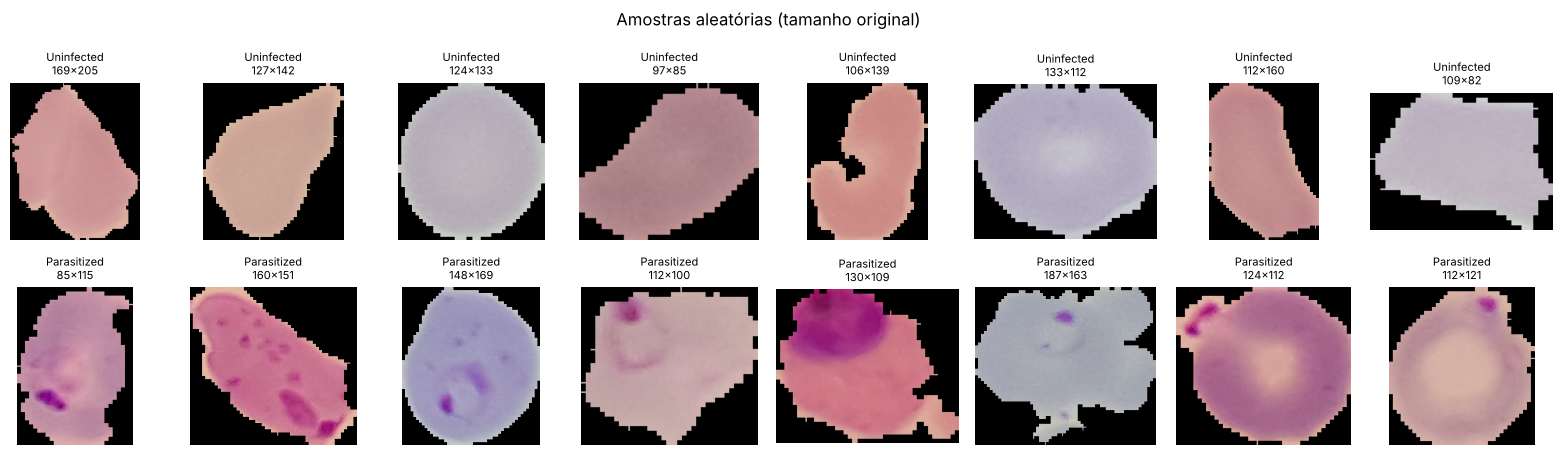

In [ ]:
# Mostra 8 imagens sorteadas de cada classe, no tamanho original
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for i, c in enumerate(CLASSES):
    amostra = df[df.classe == c].sample(8, random_state=SEED)
    for j, (_, r) in enumerate(amostra.iterrows()):
        img = Image.open(r.arquivo)
        axes[i, j].imshow(img); axes[i, j].axis('off')
        axes[i, j].set_title(f'{c}\n{img.size[0]}x{img.size[1]}', fontsize=8)
plt.suptitle('Amostras aleatórias (tamanho original)')
plt.tight_layout(); salvar('eda_amostras.png'); plt.show()

**O que observar:** nas *Parasitized*, a mancha roxa (o anel do parasita) às vezes está **na borda** da célula, que é a forma *accolé* típica do *P. falciparum*. O **fundo preto** é a área fora da célula recortada. A cor da hemácia varia entre rosa e lilás de uma lâmina para outra (variação de coloração).

### 3.2 Resolução das imagens (tamanho original)

In [ ]:
# Lemos só o cabeçalho de cada arquivo (rápido) e calculamos um hash MD5 para achar duplicatas.
# MD5 = "impressão digital" do arquivo: dois arquivos idênticos têm o mesmo MD5.
larg, alt, hashes = [], [], []
for p in tqdm(df.arquivo, desc='lendo tamanhos'):
    with Image.open(p) as im:
        w, h = im.size
    larg.append(w); alt.append(h)
    with open(p, 'rb') as f:
        hashes.append(hashlib.md5(f.read()).hexdigest())
df['largura'], df['altura'], df['md5'] = larg, alt, hashes
df['proporcao'] = df.largura / df.altura      # 1,0 = imagem quadrada

# Estatísticas por classe (média, desvio, mínimo, quartis, máximo)
df.groupby('classe')[['largura', 'altura', 'proporcao']].describe().T.round(1)

lendo tamanhos:   0%|          | 0/27558 [00:00<?, ?it/s]

classe           Parasitized  Uninfected
largura   count      13779.0     13779.0
          mean         133.6       131.3
          std           21.2        18.7
          min           46.0        49.0
          25%          121.0       118.0
          50%          133.0       130.0
          75%          145.0       142.0
          max          394.0       247.0
altura    count      13779.0     13779.0
          mean         134.4       131.6
          std           22.0        19.1
          min           40.0        49.0
          25%          121.0       121.0
          50%          133.0       130.0
          75%          145.0       142.0
          max          385.0       235.0
proporcao count      13779.0     13779.0
          mean           1.0         1.0
          std            0.2         0.1
          min            0.5         0.5
          25%            0.9         0.9
          50%            1.0         1.0
          75%            1.1         1.1
          max            2.6         2.1

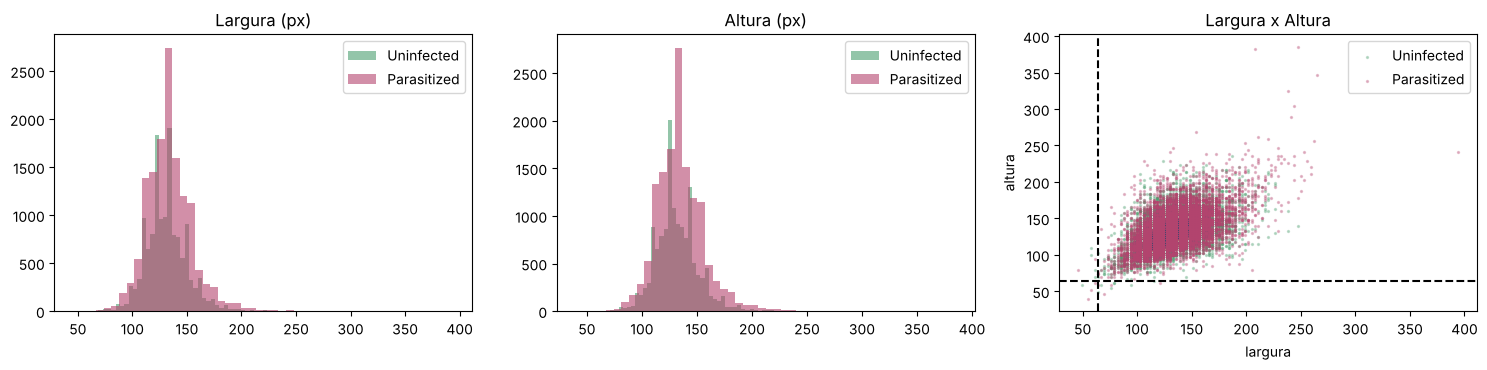

Mediana: 130 x 130 px
Menor: 46 x 40 | Maior: 394 x 385
Imagens menores que 64px em algum lado: 20


In [ ]:
# Histogramas de largura e altura + dispersão largura x altura
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for c, cor in zip(CLASSES, ['#4C9F70', '#B5446E']):
    s = df[df.classe == c]
    ax[0].hist(s.largura, bins=50, alpha=.6, label=c, color=cor)
    ax[1].hist(s.altura,  bins=50, alpha=.6, label=c, color=cor)
    ax[2].scatter(s.largura, s.altura, s=2, alpha=.3, label=c, color=cor)
ax[0].set_title('Largura (px)'); ax[1].set_title('Altura (px)')
ax[2].set_title('Largura x Altura'); ax[2].set_xlabel('largura'); ax[2].set_ylabel('altura')
ax[2].axvline(IMG_SIZE, ls='--', c='k'); ax[2].axhline(IMG_SIZE, ls='--', c='k')   # linhas tracejadas = 64 px
for a in ax: a.legend()
plt.tight_layout(); salvar('eda_resolucao.png'); plt.show()

print(f'Mediana: {df.largura.median():.0f} x {df.altura.median():.0f} px')
print(f'Menor: {df.largura.min()} x {df.altura.min()} | Maior: {df.largura.max()} x {df.altura.max()}')
print(f'Imagens menores que {IMG_SIZE}px em algum lado: {((df.largura < IMG_SIZE) | (df.altura < IMG_SIZE)).sum()}')

### 3.3 Problemas do conjunto: duplicatas e viés de lâmina

### 📘 Teoria: vazamento de dados (*data leakage*)
**Vazamento** é quando informação do conjunto de teste "vaza" para o treino. O modelo parece ótimo, mas só porque já viu algo muito parecido. Aqui há dois riscos:
1. **Imagens idênticas** em treino e teste.
2. **Células da mesma lâmina** em treino e teste: elas têm a mesma coloração, iluminação e câmera. A rede pode aprender "o jeito da lâmina" em vez do parasita.

In [ ]:
# Duplicatas exatas (mesmo conteúdo de arquivo = mesmo MD5)
dup = df[df.duplicated('md5', keep=False)]
print('Imagens com conteúdo duplicado:', len(dup))
if len(dup):
    conflito = dup.groupby('md5').classe.nunique()
    print('Grupos de duplicatas com rótulos DIFERENTES:', (conflito > 1).sum())

# Removemos duplicatas exatas (mantemos a primeira) para não haver a mesma imagem em treino e teste
antes = len(df)
df = df.drop_duplicates('md5').reset_index(drop=True)
print(f'Após remover duplicatas: {len(df)} imagens (removidas {antes - len(df)})')

Imagens com conteúdo duplicado: 0
Após remover duplicatas: 27558 imagens (removidas 0)


Número de lâminas: 201
Lâminas com só uma classe: 50
Lâminas com as duas classes: 151
Imagens por lâmina: média 137 | min 65 | max 702


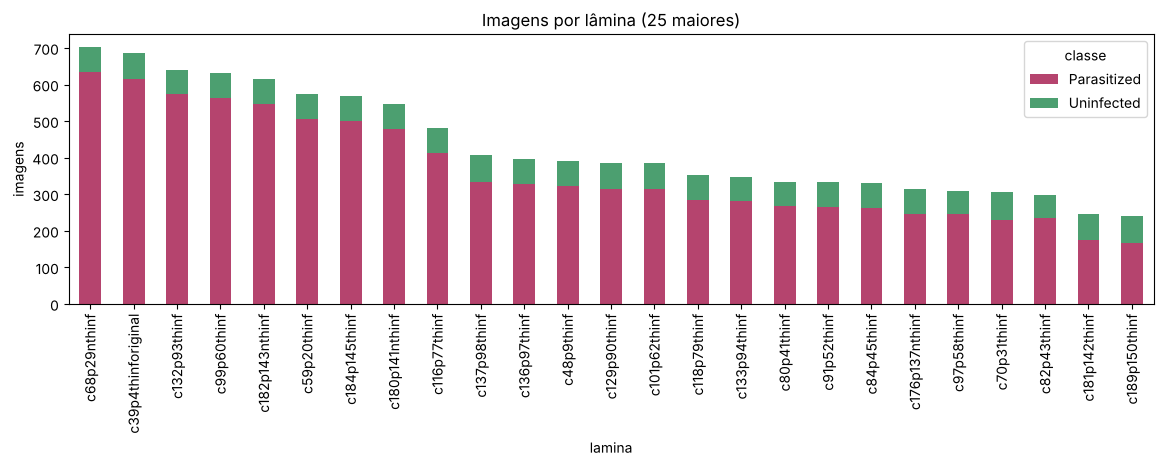

In [ ]:
# Quantas lâminas existem e se cada lâmina tem as duas classes
por_lamina = df.groupby('lamina').classe.agg(['nunique', 'size'])
print('Número de lâminas:', len(por_lamina))
print('Lâminas com só uma classe:', (por_lamina['nunique'] == 1).sum())
print('Lâminas com as duas classes:', (por_lamina['nunique'] == 2).sum())
print('Imagens por lâmina: média %.0f | min %d | max %d' % (por_lamina['size'].mean(), por_lamina['size'].min(), por_lamina['size'].max()))

# Gráfico: as 25 lâminas com mais imagens, separadas por classe
tab = pd.crosstab(df.lamina, df.classe)
tab.loc[tab.sum(axis=1).sort_values(ascending=False).index[:25]].plot.bar(stacked=True, figsize=(14, 3.5),
                                                                       color=['#B5446E', '#4C9F70'])
plt.title('Imagens por lâmina (25 maiores)'); plt.ylabel('imagens')
salvar('eda_laminas.png'); plt.show()

**Achados da análise exploratória** (valores da nossa execução; o conjunto é fixo, então devem se repetir)
- **Balanceamento:** 13.779 imagens por classe (50% / 50%). Acurácia é uma métrica razoável, mas ainda olhamos precisão e revocação por classe.
- **Resolução variável:** mediana 130×130 px, de 46×40 até 394×385 px. A proporção largura/altura tem mediana 1,0 (células quase redondas), então redimensionar para 64×64 distorce pouco. Só 20 imagens têm algum lado menor que 64 px.
- **Duplicatas:** nenhuma duplicata exata pelo MD5.
- **Viés de lâmina/paciente:** são 201 lâminas. **50 lâminas têm só a classe *Uninfected*:** são as dos **50 pacientes saudáveis**. As outras 151 (pacientes infectados) têm células das duas classes, porque nem toda hemácia de um paciente doente está infectada. Por isso a divisão é **por lâmina**: nenhuma lâmina aparece em mais de um conjunto.
- **Possível ruído de rótulo:** a rotulagem foi manual, e uma revisão posterior do conjunto encontrou rótulos errados. Vamos procurar sinais disso na análise de erros.

## 4. Pré-processamento e divisão sem vazamento

### 📘 Teoria: treino, validação e teste
| Conjunto | Para que serve | Quando é usado |
|---|---|---|
| **Treino** | a rede ajusta os pesos olhando estas imagens | em todas as épocas |
| **Validação** | comparar experimentos e escolher o melhor modelo | ao fim de cada época e na escolha |
| **Teste** | medir o desempenho final de forma honesta | **uma única vez**, no fim |

Se usássemos o teste para escolher o modelo, estaríamos "ajustando" o modelo ao teste, e o resultado final ficaria otimista.

### 🔧 O que o código faz
- Cada imagem é convertida para RGB e redimensionada para **64×64** (interpolação bilinear = calcula cada novo pixel pela média ponderada dos 4 vizinhos). Guardamos em `uint8` (0 a 255) para economizar memória; a normalização para [0, 1] é feita **dentro do modelo** (camada `Rescaling`).
- **`StratifiedGroupKFold`**: divide em 5 partes ("folds") respeitando os **grupos** (lâminas: nenhuma lâmina é dividida) e tentando manter a **proporção das classes** (estratificado). Usamos 1 fold como teste (~20%); depois repetimos no resto para tirar a validação (~16%). Sobra ~64% para treino.

In [ ]:
def carregar(p):
    # abre, garante 3 canais (RGB), redimensiona para 64x64 e converte em array numpy
    with Image.open(p) as im:
        return np.asarray(im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

# Cache: se já redimensionamos antes, reaproveita o arquivo .npz (economiza tempo)
cache = f'malaria_{IMG_SIZE}px.npz'
if os.path.exists(cache) and len(np.load(cache)['y']) == len(df):
    X = np.load(cache)['X']
else:
    X = np.stack([carregar(p) for p in tqdm(df.arquivo, desc='redimensionando')])
    np.savez_compressed(cache, X=X, y=df.label.values)
y = df.label.values           # rótulos (0 ou 1)
grupos = df.lamina.values     # lâmina de cada imagem
print('X:', X.shape, X.dtype, '| memória: %.0f MB' % (X.nbytes / 1e6))   # (n_imagens, 64, 64, 3)

redimensionando:   0%|          | 0/27558 [00:00<?, ?it/s]

X: (27558, 64, 64, 3) uint8 | memória: 339 MB


In [ ]:
# 1) separa o TESTE (1 dos 5 folds = ~20%)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_resto, idx_test = next(sgkf.split(X, y, grupos))
# 2) do restante, separa a VALIDAÇÃO (~20% do resto = ~16% do total)
sgkf2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
i_tr, i_va = next(sgkf2.split(X[idx_resto], y[idx_resto], grupos[idx_resto]))
idx_train, idx_val = idx_resto[i_tr], idx_resto[i_va]

# checagem de vazamento: nenhuma lâmina em comum (se houver, o assert interrompe o notebook)
g_tr, g_va, g_te = set(grupos[idx_train]), set(grupos[idx_val]), set(grupos[idx_test])
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), 'Vazamento de lâmina!'

X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]

# Tabela-resumo da divisão
resumo_split = pd.DataFrame({
    'imagens': [len(idx_train), len(idx_val), len(idx_test)],
    '% do total': [round(100 * len(i) / len(y), 1) for i in (idx_train, idx_val, idx_test)],
    'lâminas': [len(g_tr), len(g_va), len(g_te)],
    '% Parasitized': [round(100 * v.mean(), 1) for v in (y_train, y_val, y_test)],
}, index=['treino', 'validação', 'teste'])
resumo_split

,imagens,% do total,lâminas,% Parasitized
treino,17597,63.9,128,50.2
validação,4479,16.3,33,49.3
teste,5482,19.9,40,50.0


### 🔧 `tf.data`: entregando as imagens à rede em lotes
A rede não recebe todas as imagens de uma vez: recebe **lotes (batches)** de 64. Para o treino, as imagens são **embaralhadas a cada época** (com semente fixa), para a rede não decorar uma ordem. `prefetch` prepara o próximo lote enquanto o atual é processado.

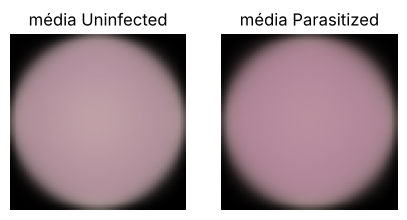

In [ ]:
# Imagem média de cada classe (no conjunto de treino): mostra diferenças "médias" de cor
fig, ax = plt.subplots(1, 2, figsize=(5, 2.6))
for i, c in enumerate(CLASSES):
    ax[i].imshow(X_train[y_train == i].mean(0).astype(np.uint8)); ax[i].set_title(f'média {c}'); ax[i].axis('off')
salvar('eda_imagem_media.png'); plt.show()

# tf.data: embaralha só o treino, com semente fixa
def ds(Xa, ya, embaralhar=False):
    d = tf.data.Dataset.from_tensor_slices((Xa, ya.astype('float32')))
    if embaralhar:
        d = d.shuffle(len(Xa), seed=SEED, reshuffle_each_iteration=True)
    return d.batch(BATCH).prefetch(tf.data.AUTOTUNE)

ds_train      = ds(X_train, y_train, embaralhar=True)
ds_train_eval = ds(X_train, y_train)          # para medir acurácia de treino sem aumento de dados
ds_val        = ds(X_val, y_val)

## 5. Arquitetura da CNN (construída camada por camada)

### 📘 Teoria: como uma CNN "enxerga" uma imagem
Uma imagem colorida 64×64 é um **tensor 64×64×3**: altura × largura × canais (R, G e B), com valores de 0 a 255.

**Convolução (`Conv2D`)**: um **filtro** (kernel) pequeno, por exemplo 3×3×3, desliza pela imagem. Em cada posição, multiplica seus 27 pesos pelos 27 pixels embaixo dele e soma tudo (mais um *bias*). O resultado é **um número por posição**, formando um **mapa de características** (*feature map*). Um filtro que aprendeu a detectar "ponto roxo escuro" gera um mapa que "acende" onde há pontos roxos.
- Uma camada com **16 filtros** gera **16 mapas** → saída 64×64×16.
- **Os pesos dos filtros não são definidos por nós: são aprendidos no treino.**
- `padding='same'`: completa a borda com zeros para a saída ter o **mesmo tamanho** da entrada.

**ReLU** (`max(0, x)`): zera valores negativos e mantém os positivos. Introduz **não linearidade**, sem a qual várias camadas equivaleriam a uma só.

**MaxPooling 2×2**: divide o mapa em quadrados 2×2 e fica só com o **maior valor** de cada um. Resultado: mapa com **metade da altura e da largura**. Mantém a informação "tem ponto roxo nesta região" e descarta a posição exata (tolerância a pequenos deslocamentos).

**Empilhando blocos**: as primeiras camadas detectam coisas simples (bordas, manchas de cor); as seguintes combinam essas coisas em padrões mais complexos (anel com ponto, textura). A cada bloco o mapa fica **menor** e com **mais canais**: 64→32→16→8 de lado; 16→32→64 filtros.

**Flatten**: "achata" o mapa 8×8×64 num vetor de 4.096 números.

**Dense (totalmente conectada)**: cada neurônio recebe **todos** os 4.096 valores, multiplica por pesos e soma. Combina as características para decidir.

**Saída sigmoid**: um único neurônio com a função sigmoide `1/(1+e^-x)`, que transforma qualquer número em um valor entre 0 e 1 = **probabilidade de *Parasitized***. Se ≥ 0,5, a previsão é *Parasitized*.

### 📘 Como a rede aprende
1. **Função de perda (*loss*)**: `binary_crossentropy` mede o quanto a probabilidade prevista está longe do rótulo. Ex.: rótulo 1 e previsão 0,9 → perda pequena; previsão 0,1 → perda grande.
2. **Retropropagação (*backpropagation*)**: calcula o **gradiente**, isto é, em que direção mudar cada peso para a perda diminuir.
3. **Otimizador (Adam)**: dá um passo nessa direção. O tamanho do passo é a **taxa de aprendizado** (*learning rate*, 0,001). Adam ajusta o passo de cada peso automaticamente.
4. Repete para cada lote; ver o treino inteiro uma vez = **1 época**.

### 📘 Escolhas do baseline
| Escolha | Justificativa |
|---|---|
| Entrada 64×64×3 | mantém a cor (o parasita é roxo na coloração Giemsa) e cabe na memória do Colab |
| `Rescaling(1/255)` | normaliza pixels para [0, 1]; redes treinam melhor com valores pequenos |
| Kernel 3×3, `padding='same'` | kernel pequeno capta bordas e pontos (o anel do parasita é pequeno); `same` mantém o tamanho antes do pooling |
| Filtros 16 → 32 → 64 | dobra a cada bloco: o mapa fica menor e mais "profundo", com padrões mais complexos |
| MaxPooling 2×2 | reduz o mapa pela metade (64→32→16→8), dá invariância a pequenos deslocamentos e reduz parâmetros |
| ReLU | não satura, treina rápido |
| Saída 1 neurônio sigmoid + `binary_crossentropy` | problema binário: saída = probabilidade de **Parasitized** |
| Adam, lr = 1e-3 | otimizador padrão, robusto |

### 🔧 O que o código faz
A função `construir_cnn` monta a rede a partir de um **dicionário de configuração** (`cfg`). Assim cada experimento muda **apenas um item** do dicionário, e o resto fica igual.

In [ ]:
# Configuração do baseline: nada de augmentation, dropout ou BN; 3 blocos; Adam com lr 0,001
BASE = dict(aug=False, dropout=0.0, bn=False, blocos=3, lr=1e-3, otimizador='adam', early_stopping=False)
FILTROS = [16, 32, 64, 128]   # nº de filtros de cada bloco (o 4º só é usado se blocos=4)

def construir_cnn(cfg, nome='cnn'):
    m = keras.Sequential(name=nome)                     # rede "em sequência": camada após camada
    m.add(keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))   # entrada: imagem 64x64 com 3 canais
    if cfg['aug']:   # só atua no treino; na avaliação estas camadas não fazem nada
        m.add(layers.RandomFlip('horizontal_and_vertical', seed=SEED, name='aug_flip'))       # espelha
        m.add(layers.RandomRotation(0.5, fill_mode='constant', seed=SEED, name='aug_rot'))   # até ±180°
        m.add(layers.RandomZoom(0.1, fill_mode='constant', seed=SEED, name='aug_zoom'))     # zoom ±10%
    m.add(layers.Rescaling(1. / 255, name='rescale'))   # pixels de 0-255 para 0-1
    for i in range(cfg['blocos']):                      # cada bloco: Conv -> (BN) -> ReLU -> MaxPool
        m.add(layers.Conv2D(FILTROS[i], 3, padding='same', use_bias=not cfg['bn'], name=f'conv{i+1}'))
        if cfg['bn']:
            m.add(layers.BatchNormalization(name=f'bn{i+1}'))   # com BN o bias da conv é dispensável
        m.add(layers.Activation('relu', name=f'relu{i+1}'))
        m.add(layers.MaxPooling2D(2, name=f'pool{i+1}'))      # metade da altura e da largura
    m.add(layers.Flatten(name='flatten'))                     # mapa 3D -> vetor 1D
    m.add(layers.Dense(64, activation='relu', name='dense'))  # camada densa de 64 neurônios
    if cfg['dropout'] > 0:
        m.add(layers.Dropout(cfg['dropout'], name='dropout'))
    m.add(layers.Dense(1, activation='sigmoid', name='saida'))   # probabilidade de Parasitized

    # Otimizador: Adam (padrão) ou SGD com momento
    opt = (keras.optimizers.Adam(cfg['lr']) if cfg['otimizador'] == 'adam'
           else keras.optimizers.SGD(cfg['lr'], momentum=0.9))
    m.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    return m

baseline_demo = construir_cnn(BASE, 'baseline')
baseline_demo.summary()

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescale (Rescaling)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 285,857 (1.09 MB)

 Trainable params: 285,857 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Tabela camada a camada: tamanho do mapa de características e nº de parâmetros
def tabela_camadas(m):
    return pd.DataFrame([{'camada': l.name, 'tipo': type(l).__name__,
                          'saída': tuple(l.output.shape[1:]), 'parâmetros': l.count_params()}
                         for l in m.layers])
tc = tabela_camadas(baseline_demo)
print('Total de parâmetros:', f"{baseline_demo.count_params():,}".replace(',', '.'))
tc

Total de parâmetros: 285.857


,camada,tipo,saída,parâmetros
0,rescale,Rescaling,"(64, 64, 3)",0
1,conv1,Conv2D,"(64, 64, 16)",448
2,relu1,Activation,"(64, 64, 16)",0
3,pool1,MaxPooling2D,"(32, 32, 16)",0
4,conv2,Conv2D,"(32, 32, 32)",4640
5,relu2,Activation,"(32, 32, 32)",0
6,pool2,MaxPooling2D,"(16, 16, 32)",0
7,conv3,Conv2D,"(16, 16, 64)",18496
8,relu3,Activation,"(16, 16, 64)",0
9,pool3,MaxPooling2D,"(8, 8, 64)",0


### 📘 Como calcular os parâmetros (pergunta comum na apresentação)
- **Conv2D:** `(altura do kernel × largura × canais de entrada + 1 de bias) × nº de filtros`
  - conv1: (3·3·3 + 1) · 16 = **448**
  - conv2: (3·3·16 + 1) · 32 = **4.640**
  - conv3: (3·3·32 + 1) · 64 = **18.496**
- **MaxPooling, ReLU, Flatten, Rescaling:** **0** parâmetros (só fazem contas fixas).
- **Dense:** `(entradas + 1) × neurônios` → (4.096 + 1) · 64 = **262.208**; saída: (64 + 1) · 1 = **65**.
- **Total: 285.857.** Repare que **92% dos parâmetros estão na Dense**: é ali que a rede tem mais "capacidade de decorar", o lugar mais sujeito a *overfitting*.

**Tamanho dos mapas:** 64×64×3 → conv1 64×64×16 → pool 32×32×16 → conv2 32×32×32 → pool 16×16×32 → conv3 16×16×64 → pool 8×8×64 → flatten 4.096 → dense 64 → saída 1.

## 6. Experimentos: um fator por vez

### 📘 Teoria: *overfitting* e as técnicas testadas
**Overfitting (sobreajuste)** é quando a rede **decora** o treino em vez de aprender o padrão geral. Sinal típico: a acurácia de treino continua subindo, mas a de validação para ou cai, e a **perda de validação começa a subir**. Chamamos de **gap** a diferença acurácia de treino − acurácia de validação.

| Técnica | O que faz | Por que poderia ajudar aqui |
|---|---|---|
| **Data augmentation** | a cada época, mostra versões **giradas, espelhadas e com zoom** das imagens de treino (geradas na memória, não salvas) | uma célula girada continua sendo a mesma célula; a rede vê "mais" exemplos e decora menos |
| **Dropout** | durante o treino, **desliga aleatoriamente** uma fração dos neurônios (aqui 50%) a cada lote | a rede não pode depender de poucos neurônios específicos; reduz a decoreba |
| **Batch Normalization** | normaliza a saída de cada camada (média ~0, desvio ~1) dentro do lote | treino mais estável e rápido; pode reduzir o efeito das diferenças de coloração |
| **Profundidade (+1 bloco)** | acrescenta um 4º bloco Conv(128)+Pool | padrões mais complexos; o mapa final fica 4×4×128 = 2.048 entradas, e a Dense encolhe |
| **Taxa de aprendizado** | tamanho do passo de atualização dos pesos (0,001 → 0,0003) | passos menores oscilam menos, mas aprendem mais devagar |
| **Early stopping** | acompanha a perda de validação; se não melhorar por 4 épocas seguidas, **para** e **restaura os pesos da melhor época** | evita usar pesos de épocas em que a rede já estava decorando |

### 🔧 Procedimento (busca gulosa)
1. Treinar o **baseline** e medir na **validação**.
2. Cada experimento parte da **melhor configuração até o momento** e altera **um único fator**.
3. Se a acurácia de validação melhorar, a mudança é **mantida**; senão, é **descartada**.
4. Todos usam a mesma semente, os mesmos dados e no máximo `EPOCHS` épocas.

O conjunto de **teste não é usado aqui**.

In [ ]:
# Lista de experimentos: cada um muda UM item da configuração
EXPERIMENTOS = [
    dict(id='E1', fator='Data augmentation (flip, rotação, zoom)', mudanca=dict(aug=True),
         hipotese='Células não têm orientação fixa; girar/espelhar gera variações realistas e deve reduzir o overfitting.'),
    dict(id='E2', fator='Dropout 0,5 após a Dense', mudanca=dict(dropout=0.5),
         hipotese='A Dense concentra quase todos os parâmetros; desligar 50% dos neurônios no treino deve reduzir a decoreba.'),
    dict(id='E3', fator='Batch Normalization', mudanca=dict(bn=True),
         hipotese='Normalizar as ativações de cada bloco estabiliza e acelera o treino, e pode lidar melhor com diferenças de coloração.'),
    dict(id='E4', fator='Profundidade: +1 bloco (128 filtros)', mudanca=dict(blocos=4),
         hipotese='Mais um bloco aprende padrões mais complexos e reduz a Dense (4·4·128 entradas), com menos parâmetros.'),
    dict(id='E5', fator='Taxa de aprendizado 1e-3 → 3e-4', mudanca=dict(lr=3e-4),
         hipotese='Passos menores deixam a curva de validação mais estável e podem achar um mínimo melhor.'),
    dict(id='E6', fator='Early stopping (paciência 4)', mudanca=dict(early_stopping=True),
         hipotese='Parar quando a perda de validação para de cair e restaurar os melhores pesos evita usar épocas com overfitting.'),
]

def treinar(cfg, nome):
    keras.utils.set_random_seed(SEED)      # mesma inicialização de pesos em todos os experimentos
    modelo = construir_cnn(cfg, nome)
    cbs = []                               # "callbacks": funções chamadas ao fim de cada época
    if cfg['early_stopping']:
        cbs.append(keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True))
    t0 = time.time()
    h = modelo.fit(ds_train, validation_data=ds_val, epochs=EPOCHS, callbacks=cbs, verbose=2)   # TREINO
    tempo = time.time() - t0
    # Mede acurácia/perda no treino (sem augmentation) e na validação com os pesos finais
    tr_loss, tr_acc = modelo.evaluate(ds_train_eval, verbose=0)
    va_loss, va_acc = modelo.evaluate(ds_val, verbose=0)
    return modelo, h.history, dict(params=modelo.count_params(), epocas=len(h.history['loss']),
                                  acc_treino=tr_acc, acc_val=va_acc, loss_val=va_loss,
                                  gap=tr_acc - va_acc, tempo_s=round(tempo))

In [ ]:
modelos, historicos, linhas = {}, {}, []   # guardam os modelos, as curvas e as linhas da tabela

print('=' * 20, 'BASELINE', '=' * 20)
m, h, r = treinar(BASE, 'baseline')
modelos['Baseline'], historicos['Baseline'] = m, h
linhas.append(dict(exp='Baseline', fator='—', hipotese='Referência inicial.', **r,
                   resultado='—', conclusao='Ponto de partida.'))
melhor_cfg, melhor_nome, melhor_acc = dict(BASE), 'Baseline', r['acc_val']   # o melhor até agora

==================== BASELINE ====================


Epoch 1/20


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


275/275 - 18s - 66ms/step - accuracy: 0.7300 - loss: 0.5135 - val_accuracy: 0.9073 - val_loss: 0.2243


Epoch 2/20


275/275 - 15s - 55ms/step - accuracy: 0.9420 - loss: 0.1703 - val_accuracy: 0.9460 - val_loss: 0.1654


... (32 outputs left out)

Epoch 19/20


275/275 - 17s - 62ms/step - accuracy: 0.9931 - loss: 0.0207 - val_accuracy: 0.9462 - val_loss: 0.2083


Epoch 20/20


275/275 - 21s - 75ms/step - accuracy: 0.9964 - loss: 0.0121 - val_accuracy: 0.9509 - val_loss: 0.2480


In [ ]:
for e in EXPERIMENTOS:
    cfg = {**melhor_cfg, **e['mudanca']}   # parte da melhor configuração e troca UM item
    print('\n' + '=' * 15, e['id'], '-', e['fator'], '| parte de:', melhor_nome, '=' * 15)
    m, h, r = treinar(cfg, e['id'])
    modelos[e['id']], historicos[e['id']] = m, h
    delta = (r['acc_val'] - melhor_acc) * 100          # diferença em pontos percentuais
    if r['acc_val'] > melhor_acc:                      # melhorou na validação? então mantém
        resultado, conclusao = f'melhorou (+{delta:.2f} p.p.)', 'Mantido na configuração.'
        melhor_cfg, melhor_nome, melhor_acc = cfg, e['id'], r['acc_val']
    else:
        resultado, conclusao = f'não melhorou ({delta:+.2f} p.p.)', 'Descartado.'
    linhas.append(dict(exp=e['id'], fator=e['fator'], hipotese=e['hipotese'], **r,
                       resultado=resultado, conclusao=conclusao))

tabela = pd.DataFrame(linhas)
tabela.to_csv(os.path.join(FIG_DIR, 'tabela_experimentos.csv'), index=False)
print('\nModelo escolhido:', melhor_nome, '| config:', melhor_cfg)


=============== E1 - Data augmentation (flip, rotação, zoom) | parte de: Baseline ===============
Epoch 1/20


275/275 - 26s - 94ms/step - accuracy: 0.7053 - loss: 0.5535 - val_accuracy: 0.9060 - val_loss: 0.2583


Epoch 2/20


275/275 - 24s - 87ms/step - accuracy: 0.9344 - loss: 0.1886 - val_accuracy: 0.9466 - val_loss: 0.1481


Epoch 3/20


275/275 - 40s - 146ms/step - accuracy: 0.9491 - loss: 0.1553 - val_accuracy: 0.9551 - val_loss: 0.1328


... (232 outputs left out)

275/275 - 26s - 95ms/step - accuracy: 0.9645 - loss: 0.1002 - val_accuracy: 0.9672 - val_loss: 0.1023


Epoch 20/20


275/275 - 26s - 96ms/step - accuracy: 0.9651 - loss: 0.1016 - val_accuracy: 0.9609 - val_loss: 0.1114



Modelo escolhido: E6 | config: {'aug': True, 'dropout': 0.0, 'bn': False, 'blocos': 4, 'lr': 0.001, 'otimizador': 'adam', 'early_stopping': True}


In [ ]:
# Tabela de experimentos (valores reais da execução), em porcentagem
fmt = tabela.copy()
for c in ['acc_treino', 'acc_val', 'gap']:
    fmt[c] = (fmt[c] * 100).round(2)
fmt['loss_val'] = fmt['loss_val'].round(4)
fmt = fmt.rename(columns={'acc_treino': 'acc treino %', 'acc_val': 'acc val %', 'gap': 'gap treino-val (p.p.)',
                          'loss_val': 'loss val', 'tempo_s': 'tempo (s)', 'epocas': 'épocas'})
pd.set_option('display.max_colwidth', 90)
fmt

,exp,fator,hipotese,params,épocas,acc treino %,acc val %,loss val,gap treino-val (p.p.),tempo (s),resultado,conclusao
0,Baseline,—,Referência inicial.,285857,20,99.86,95.09,0.2480,4.77,361,—,Ponto de partida.
1,E1,"Data augmentation (flip, rotação, zoom)",Células não têm orientação fixa; girar/espelhar gera variações realistas e deve reduzi...,285857,20,96.49,96.07,0.1120,0.42,695,melhorou (+0.98 p.p.),Mantido na configuração.
2,E2,"Dropout 0,5 após a Dense",A Dense concentra quase todos os parâmetros; desligar 50% dos neurônios no treino deve...,285857,20,96.42,95.98,0.1131,0.44,648,não melhorou (-0.09 p.p.),Descartado.
3,E3,Batch Normalization,"Normalizar as ativações de cada bloco estabiliza e acelera o treino, e pode lidar melh...",286193,20,96.35,95.65,0.1294,0.70,805,não melhorou (-0.42 p.p.),Descartado.
4,E4,Profundidade: +1 bloco (128 filtros),"Mais um bloco aprende padrões mais complexos e reduz a Dense (4·4·128 entradas), com m...",228641,20,96.49,96.23,0.1051,0.27,635,melhorou (+0.16 p.p.),Mantido na configuração.
5,E5,Taxa de aprendizado 1e-3 → 3e-4,Passos menores deixam a curva de validação mais estável e podem achar um mínimo melhor.,228641,20,95.89,95.51,0.1305,0.37,639,não melhorou (-0.71 p.p.),Descartado.
6,E6,Early stopping (paciência 4),Parar quando a perda de validação para de cair e restaurar os melhores pesos evita usa...,228641,20,96.51,96.72,0.1023,-0.21,635,melhorou (+0.49 p.p.),Mantido na configuração.


**Como interpretar a tabela** (escrever a discussão com os números de vocês)
- **Gap do baseline:** se a acurácia de treino chega perto de 100% e a de validação fica bem abaixo, é **overfitting**.
- **Augmentation:** se o gap cair muito, a hipótese se confirmou: a rede parou de decorar.
- **Dropout e BN depois da augmentation:** se não ajudarem, uma explicação provável é que o overfitting **já foi resolvido** pela augmentation, e não sobrou o que corrigir.
- **Diferenças menores que ~0,5 p.p.** podem ser apenas **variação aleatória** (outra semente poderia inverter o resultado). Vale dizer isso na apresentação.
- **Early stopping:** confiram na saída do treino se ele **realmente parou** antes de 20 épocas. Na nossa execução ele **não parou**: o ganho veio do `restore_best_weights`, que no Keras 3 restaura os pesos da melhor época mesmo quando o treino vai até o fim.

### 📘 Como ler as curvas de aprendizado
- **Perda de treino** caindo sempre = a rede está aprendendo o treino.
- **Perda de validação** caindo junto = está **generalizando**.
- **Perda de validação subindo enquanto a de treino cai** = **overfitting**.
- Curvas de treino e validação **próximas** = bom sinal.

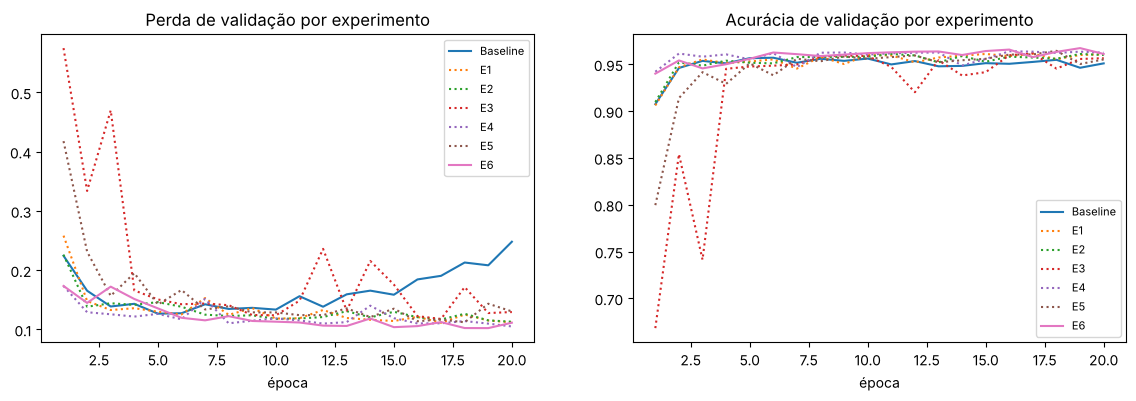

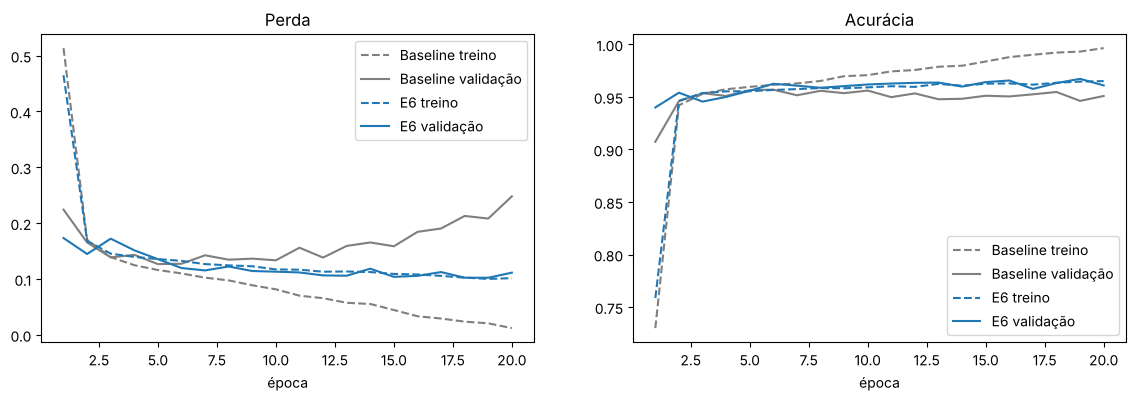

In [ ]:
# Curvas de aprendizado: validação de todos os experimentos
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for nome, h in historicos.items():
    ls = '-' if nome in ('Baseline', melhor_nome) else ':'   # linha cheia = baseline e final
    ep = range(1, len(h['loss']) + 1)
    ax[0].plot(ep, h['val_loss'], ls, label=nome); ax[1].plot(ep, h['val_accuracy'], ls, label=nome)
ax[0].set_title('Perda de validação por experimento'); ax[1].set_title('Acurácia de validação por experimento')
for a in ax: a.set_xlabel('época'); a.legend(fontsize=8)
salvar('curvas_todos_experimentos.png'); plt.show()

# Baseline x modelo final: treino (tracejado) e validação (cheio)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for nome, cor in [('Baseline', 'tab:gray'), (melhor_nome, 'tab:blue')]:
    h = historicos[nome]; ep = range(1, len(h['loss']) + 1)
    ax[0].plot(ep, h['loss'], '--', c=cor, label=f'{nome} treino'); ax[0].plot(ep, h['val_loss'], c=cor, label=f'{nome} validação')
    ax[1].plot(ep, h['accuracy'], '--', c=cor, label=f'{nome} treino'); ax[1].plot(ep, h['val_accuracy'], c=cor, label=f'{nome} validação')
ax[0].set_title('Perda'); ax[1].set_title('Acurácia')
for a in ax: a.set_xlabel('época'); a.legend()
salvar('curvas_baseline_vs_final.png'); plt.show()

## 7. Comparação com transfer learning (somente referência)

### 📘 Teoria
**Transfer learning** = reaproveitar uma rede já treinada em milhões de imagens (ImageNet: fotos de objetos, animais...). As camadas convolucionais dela já sabem detectar bordas, texturas e formas. Congelamos esses pesos e treinamos só uma "cabeça" nova para o nosso problema.

Conforme o enunciado, o modelo pré-treinado entra **só como comparação**. Usamos a **MobileNetV2** congelada, avaliada **na validação** (o teste continua reservado ao modelo final). Ela precisa de entrada ≥ 96×96 e de pixels em [-1, 1], por isso as camadas `Resizing` e `Rescaling`.

In [ ]:
if RODAR_TRANSFER:
    keras.utils.set_random_seed(SEED)
    base_tl = keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(96, 96, 3))
    base_tl.trainable = False                                        # congela os pesos pré-treinados
    tl = keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Resizing(96, 96),                                     # menor tamanho com pesos ImageNet
        layers.Rescaling(1. / 127.5, offset=-1),                     # MobileNetV2 espera [-1, 1]
        base_tl,
        layers.GlobalAveragePooling2D(),                             # média de cada mapa -> vetor
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid'),
    ], name='mobilenetv2_tl')
    tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h_tl = tl.fit(ds_train, validation_data=ds_val, epochs=5, verbose=2)
    va_loss, va_acc = tl.evaluate(ds_val, verbose=0)
    comp = pd.DataFrame([
        dict(modelo=f'CNN do grupo ({melhor_nome})', parametros=modelos[melhor_nome].count_params(),
             parametros_treinaveis=modelos[melhor_nome].count_params(), acc_val=round(melhor_acc * 100, 2)),
        dict(modelo='MobileNetV2 congelada (5 épocas)', parametros=tl.count_params(),
             parametros_treinaveis=int(sum(np.prod(w.shape) for w in tl.trainable_weights)),
             acc_val=round(va_acc * 100, 2)),
    ])
    comp.to_csv(os.path.join(FIG_DIR, 'comparacao_transfer.csv'), index=False)
    display(comp)

## 8. Avaliação final no conjunto de teste (uso único)

Daqui em diante usamos **só o modelo escolhido** na validação. O teste é avaliado **uma vez**; nada é ajustado depois disso.

### 📘 Teoria: matriz de confusão e métricas
Com *Parasitized* como classe **positiva**:

| | previsto Uninfected | previsto Parasitized |
|---|---|---|
| **real Uninfected** | **VN** (verdadeiro negativo) | **FP** (falso positivo: alarme falso) |
| **real Parasitized** | **FN** (falso negativo: **infecção não detectada**) | **VP** (verdadeiro positivo) |

- **Acurácia** = (VP + VN) / total → quanto acertou no geral.
- **Precisão** (de uma classe) = acertos da classe / tudo que foi **previsto** como essa classe. Precisão de *Parasitized* = VP / (VP + FP): "quando o modelo diz infectada, quanto ele acerta?"
- **Revocação / recall** (de uma classe) = acertos da classe / tudo que **realmente é** dessa classe. Revocação de *Parasitized* = VP / (VP + FN) = **sensibilidade**: "das infectadas, quantas o modelo encontra?" Revocação de *Uninfected* = **especificidade**.
- **F1-score** = média harmônica de precisão e revocação: `2·P·R / (P + R)`. Só é alto se as duas forem altas.
- **AUC-ROC**: mede a capacidade de **separar** as classes considerando todos os limiares possíveis (1,0 = perfeito; 0,5 = chute).

Em diagnóstico, o **falso negativo é o erro mais grave**: o paciente infectado vai para casa sem tratamento. Por isso a **sensibilidade** é a métrica que mais importa clinicamente.

In [ ]:
modelo_final = modelos[melhor_nome]
modelo_final.save('cnn_malaria_final.keras')   # salva o modelo treinado

prob_test = modelo_final.predict(X_test, batch_size=BATCH, verbose=0).ravel()   # probabilidade de Parasitized
pred_test = (prob_test >= 0.5).astype(int)                                     # limiar 0,5 -> classe 0 ou 1

acc_test = accuracy_score(y_test, pred_test)
auc_test = roc_auc_score(y_test, prob_test)
print(f'Modelo final: {melhor_nome}')
print(f'Acurácia no teste: {acc_test*100:.2f}% | AUC-ROC: {auc_test:.4f}')

Modelo final: E6
Acurácia no teste: 95.79% | AUC-ROC: 0.9902


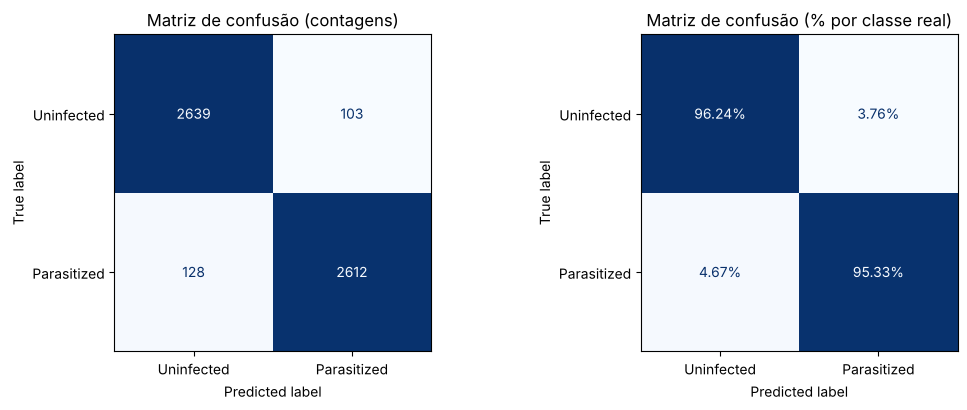

VN=2639  FP=103  FN=128  VP=2612
Falsos negativos (parasitada classificada como sadia): 128  <- o erro mais grave clinicamente


In [ ]:
# Matriz de confusão em contagens e em % por classe real (cada linha soma 100%)
cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap='Blues', values_format='d', colorbar=False)
ax[0].set_title('Matriz de confusão (contagens)')
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASSES).plot(
    ax=ax[1], cmap='Blues', values_format='.2%', colorbar=False)
ax[1].set_title('Matriz de confusão (% por classe real)')
plt.tight_layout(); salvar('matriz_confusao.png'); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'VN={tn}  FP={fp}  FN={fn}  VP={tp}')
print(f'Falsos negativos (parasitada classificada como sadia): {fn}  <- o erro mais grave clinicamente')

In [ ]:
# Relatório do scikit-learn: precisão, revocação, f1 e suporte (nº de imagens) por classe
print(classification_report(y_test, pred_test, target_names=CLASSES, digits=4))

rep = classification_report(y_test, pred_test, target_names=CLASSES, output_dict=True)
metricas = pd.DataFrame({c: {'precisão': rep[c]['precision'], 'revocação': rep[c]['recall'],
                             'f1-score': rep[c]['f1-score'],
                             'acurácia da classe': cm[i, i] / cm[i].sum(),   # acertos da classe / total da classe
                             'suporte': int(rep[c]['support'])}
                         for i, c in enumerate(CLASSES)}).T
metricas.loc['Geral (acurácia)'] = [np.nan, np.nan, np.nan, acc_test, len(y_test)]
metricas.round(4).to_csv(os.path.join(FIG_DIR, 'metricas_teste.csv'))
metricas.round(4)

              precision    recall  f1-score   support

  Uninfected     0.9537    0.9624    0.9581      2742
 Parasitized     0.9621    0.9533    0.9577      2740

    accuracy                         0.9579      5482
   macro avg     0.9579    0.9579    0.9579      5482
weighted avg     0.9579    0.9579    0.9579      5482



,precisão,revocação,f1-score,acurácia da classe,suporte
Uninfected,0.9537,0.9624,0.9581,0.9624,2742.0
Parasitized,0.9621,0.9533,0.9577,0.9533,2740.0
Geral (acurácia),NaN,NaN,NaN,0.9579,5482.0


> **Observação:** em um problema binário, a "acurácia por classe" (acertos da classe ÷ total da classe) é igual à **revocação** da classe. A revocação de *Parasitized* é a **sensibilidade**, e a revocação de *Uninfected* é a **especificidade**.

## 9. Análise de erros e Grad-CAM

### 🔧 O que o código faz
Separa os erros do teste e mostra os **mais confiantes**: falsos negativos com a menor probabilidade de *Parasitized* e falsos positivos com a maior. Erros em que o modelo tem **muita certeza** costumam revelar algo interessante: um padrão que confunde a rede ou um **rótulo errado** no conjunto. Também calcula a taxa de erro por lâmina, para ver se os erros se concentram em algumas lâminas.

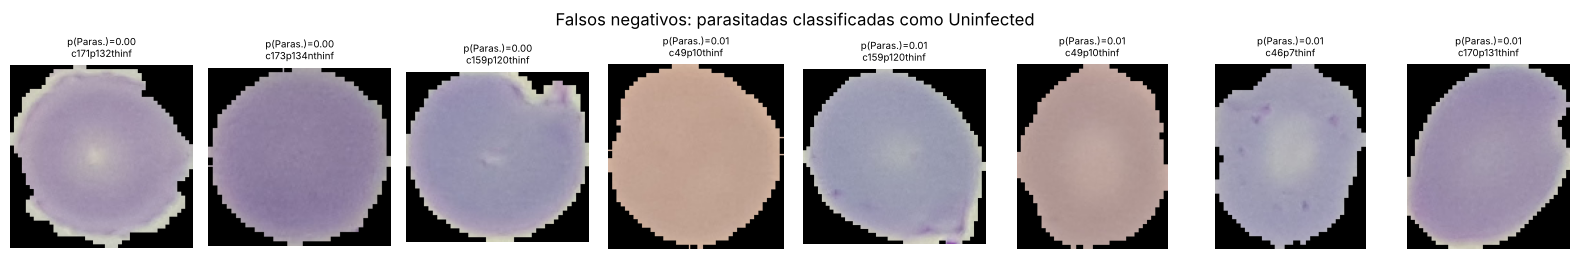

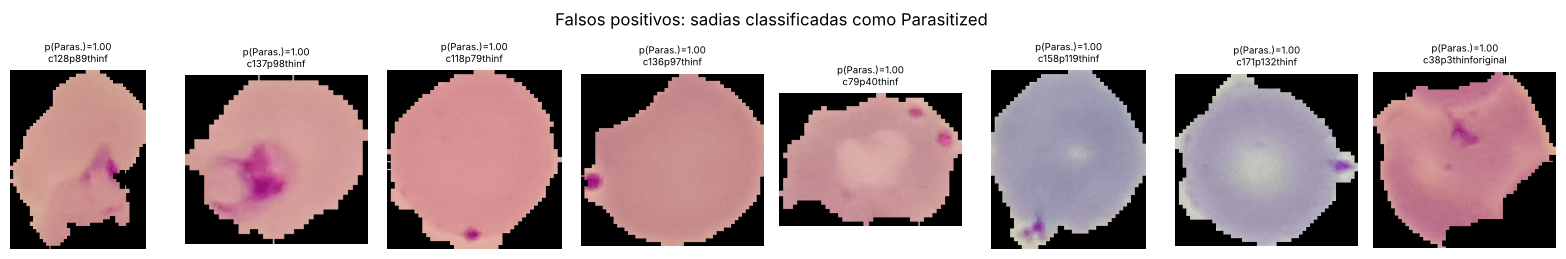

,taxa de erro,erros,imagens
lamina,,,
c68p29nthinf,0.055556,39,702
c49p10thinf,0.211538,22,104
c38p3thinforiginal,0.240000,18,75
c136p97thinf,0.037783,15,397
c128p89thinf,0.058252,12,206
c159p120thinf,0.063380,9,142
c176p137nthinf,0.028571,9,315
c115p76thinf,0.102564,8,78
c171p132thinf,0.095238,8,84


In [ ]:
# Junta as previsões à tabela das imagens de teste
df_test = df.iloc[idx_test].reset_index(drop=True).assign(prob=prob_test, pred=pred_test)
fn_df = df_test[(df_test.label == 1) & (df_test.pred == 0)].sort_values('prob')                    # mais "confiantes" no erro
fp_df = df_test[(df_test.label == 0) & (df_test.pred == 1)].sort_values('prob', ascending=False)

def grade(sub, titulo, arq, n=8):
    # mostra até n imagens com a probabilidade prevista e a lâmina
    sub = sub.head(n)
    if len(sub) == 0:
        print('Nenhum caso para', titulo); return
    fig, ax = plt.subplots(1, len(sub), figsize=(2 * len(sub), 2.6), squeeze=False)
    for a, (_, r) in zip(ax[0], sub.iterrows()):
        a.imshow(Image.open(r.arquivo)); a.axis('off')
        a.set_title(f'p(Paras.)={r.prob:.2f}\n{r.lamina}', fontsize=7)
    plt.suptitle(titulo); plt.tight_layout(); salvar(arq); plt.show()

grade(fn_df, 'Falsos negativos: parasitadas classificadas como Uninfected', 'erros_falsos_negativos.png')
grade(fp_df, 'Falsos positivos: sadias classificadas como Parasitized', 'erros_falsos_positivos.png')

# Taxa de erro por lâmina no teste (há lâminas "difíceis"?)
erro_lam = df_test.assign(erro=df_test.label != df_test.pred).groupby('lamina').erro.agg(['mean', 'sum', 'size'])
erro_lam.sort_values('sum', ascending=False).head(10).rename(columns={'mean': 'taxa de erro', 'sum': 'erros', 'size': 'imagens'})

### 📘 Teoria: Grad-CAM
O **Grad-CAM** (*Gradient-weighted Class Activation Mapping*) mostra **onde a rede olhou** para decidir:
1. Pegamos os mapas de características da **última camada convolucional** (cada mapa = onde um filtro "acendeu").
2. Calculamos o **gradiente** da saída em relação a esses mapas: quanto a probabilidade mudaria se cada ponto do mapa aumentasse.
3. A **média do gradiente** de cada mapa vira o **peso** (a importância) daquele filtro.
4. Somamos os mapas multiplicados pelos pesos, aplicamos **ReLU** (só interessa o que **aumenta** a classe prevista) e normalizamos de 0 a 1.
5. Ampliamos o resultado para 64×64 e sobrepomos à imagem: **vermelho = região mais importante**.

Se o modelo aprendeu o certo, nas parasitadas o mapa deve "acender" sobre o **anel do parasita**.

**Limitação:** o modelo final tem 4 blocos, então o último mapa é só **4×4**. Ampliado para 64×64, o mapa de calor fica "borrado": mostra a **região**, não o contorno exato.

Camada usada no Grad-CAM: relu4


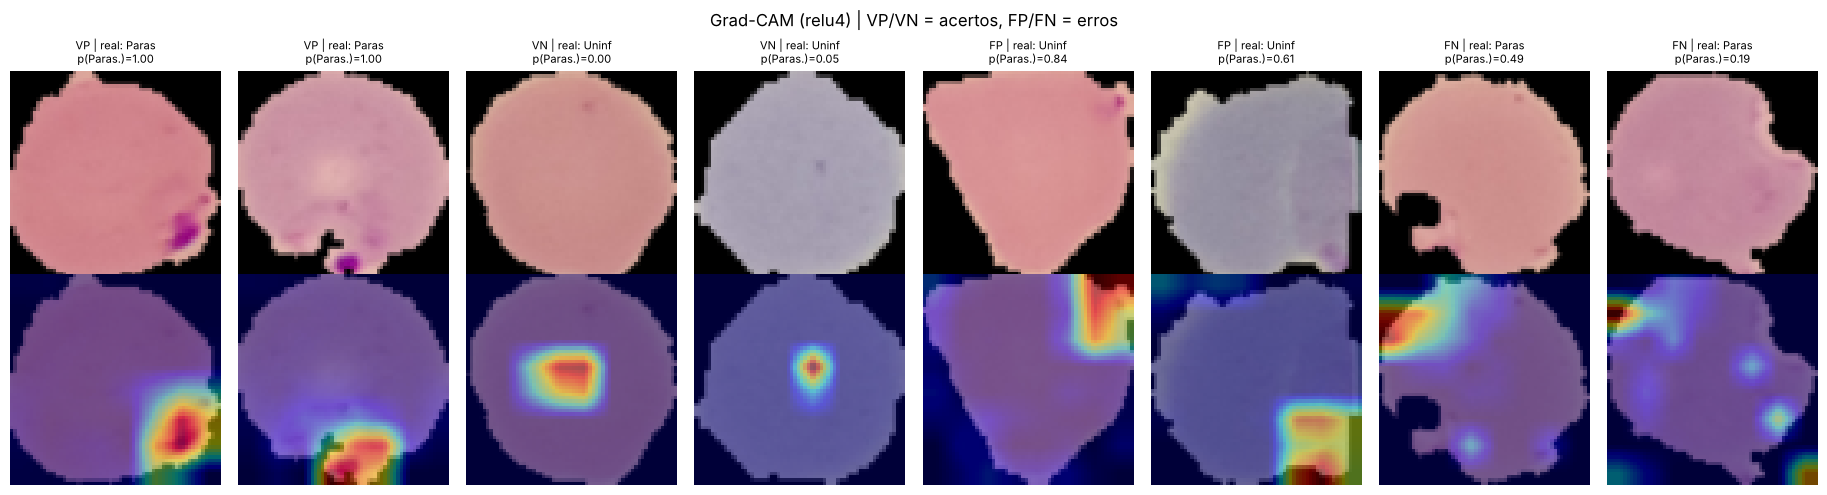

In [ ]:
# Última camada ReLU da parte convolucional (relu3 no baseline, relu4 com 4 blocos)
ultima_conv = [l.name for l in modelo_final.layers if l.name.startswith('relu')][-1]
print('Camada usada no Grad-CAM:', ultima_conv)

def grad_cam(modelo, img_uint8, camada):
    x = tf.convert_to_tensor(img_uint8[None].astype('float32'))   # [None] = adiciona a dimensão do lote
    with tf.GradientTape() as tape:            # "grava" as contas para depois calcular gradientes
        h, mapa = x, None
        for l in modelo.layers:                 # passa camada por camada (modo inferência)
            h = l(h, training=False)
            if l.name == camada:
                mapa = h                        # guarda os mapas da última conv
                tape.watch(mapa)
        p = h[0, 0]                             # probabilidade de Parasitized
        alvo = p if p >= 0.5 else 1 - p          # explica a classe PREVISTA
    grads = tape.gradient(alvo, mapa)[0]          # (h, w, filtros)
    pesos = tf.reduce_mean(grads, axis=(0, 1))    # importância de cada filtro
    cam = tf.nn.relu(tf.reduce_sum(mapa[0] * pesos, axis=-1))   # soma ponderada + ReLU
    cam = cam / (tf.reduce_max(cam) + 1e-8)                       # normaliza para 0-1
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE), method='bilinear')[..., 0]   # amplia
    return cam.numpy(), float(p)

# 2 de cada tipo: VP, VN, FP, FN (mín. 6 imagens no total)
casos = []
for nome_caso, cond in [('VP', (df_test.label == 1) & (df_test.pred == 1)),
                        ('VN', (df_test.label == 0) & (df_test.pred == 0)),
                        ('FP', (df_test.label == 0) & (df_test.pred == 1)),
                        ('FN', (df_test.label == 1) & (df_test.pred == 0))]:
    ids = np.where(cond.values)[0]
    for i in np.random.default_rng(SEED).choice(ids, size=min(2, len(ids)), replace=False):
        casos.append((nome_caso, i))
# se faltar algum tipo de erro, completa com acertos até ter pelo menos 6 imagens
extra = [i for i in np.where(df_test.label.values == df_test.pred.values)[0] if i not in [c[1] for c in casos]]
for i in extra[:max(0, 6 - len(casos))]:
    casos.append(('VP' if y_test[i] == 1 else 'VN', i))

# Linha de cima: imagem; linha de baixo: imagem + mapa de calor
fig, ax = plt.subplots(2, len(casos), figsize=(2.3 * len(casos), 5))
for k, (nome_caso, i) in enumerate(casos):
    cam, p = grad_cam(modelo_final, X_test[i], ultima_conv)
    ax[0, k].imshow(X_test[i]); ax[0, k].axis('off')
    ax[0, k].set_title(f'{nome_caso} | real: {CLASSES[y_test[i]][:5]}\np(Paras.)={p:.2f}', fontsize=8)
    ax[1, k].imshow(X_test[i]); ax[1, k].imshow(cam, cmap='jet', alpha=0.45); ax[1, k].axis('off')
plt.suptitle(f'Grad-CAM ({ultima_conv}) | VP/VN = acertos, FP/FN = erros')
plt.tight_layout(); salvar('gradcam.png'); plt.show()

**Roteiro para interpretar o Grad-CAM e os erros** (o que observamos na nossa execução, para conferirem nas figuras de vocês)
- **Verdadeiros positivos:** o mapa cobre a mancha roxa do parasita, inclusive quando ela está **na borda** (forma *accolé*). Sinal de que a rede aprendeu a pista certa.
- **Falsos positivos mais confiantes:** várias células rotuladas como *Uninfected* **têm uma mancha roxa visível**. Pode ser **rótulo errado** (parasita que o anotador não marcou) ou **artefato**: plaqueta sobreposta, resto de corante. Nesses casos a rede pode estar "certa" e o rótulo errado.
- **Falsos negativos mais confiantes:** várias células rotuladas como *Parasitized* **não mostram parasita visível**. Possível rótulo trocado, ou parasita muito pequeno/claro que sumiu ao reduzir para 64×64.
- **Erros concentrados em algumas lâminas:** lâminas com coloração diferente das do treino são mais difíceis.
- **Limitação:** não temos como **confirmar** os rótulos errados; é uma hipótese baseada na inspeção visual, coerente com a revisão publicada do conjunto.

## 10. Conclusão _(conferir com os números da execução de vocês)_

- **Resultado:** modelo final = ___ com acurácia de teste de ___%, sensibilidade (revocação de *Parasitized*) de ___% e AUC de ___.
- **Evolução:** do baseline (___% na validação) ao modelo final (___%), os fatores que mais ajudaram foram ___.
- **Comparação:** a MobileNetV2 congelada obteve ___% na validação, com ___ parâmetros treináveis.
- **Limitações do conjunto:** células já recortadas (não a lâmina inteira); só *P. falciparum* e uma única origem (Bangladesh, fotos de celular); 50 lâminas só com células sadias; rótulos possivelmente errados.
- **Limitações do modelo:** resolução reduzida a 64×64; limiar fixo de 0,5; Grad-CAM de baixa resolução; avaliação em apenas uma divisão.
- **Melhorias possíveis:** validação cruzada por lâmina; ajustar o limiar para **priorizar a sensibilidade**; normalização de coloração; 128×128 com GPU; fine-tuning de um modelo pré-treinado; usar a versão revisada do conjunto.
- **Importante:** um modelo como este **apoia** o microscopista (triagem), não o substitui.

In [ ]:
# Empacota figuras e tabelas para usar nos slides
shutil.make_archive('resultados_malaria', 'zip', FIG_DIR)
print('Arquivos gerados:', sorted(os.listdir(FIG_DIR)))
try:
    from google.colab import files
    files.download('resultados_malaria.zip')
except Exception:
    print('Fora do Colab: o zip está em resultados_malaria.zip')

Arquivos gerados: ['curvas_baseline_vs_final.png', 'curvas_todos_experimentos.png', 'eda_amostras.png', 'eda_distribuicao_classes.png', 'eda_imagem_media.png', 'eda_laminas.png', 'eda_resolucao.png', 'erros_falsos_negativos.png', 'erros_falsos_positivos.png', 'gradcam.png', 'matriz_confusao.png', 'metricas_teste.csv', 'tabela_experimentos.csv']
Fora do Colab: o zip está em resultados_malaria.zip


## 11. Log de uso de IA generativa

Mínimo de 8 interações, com pelo menos **2 situações em que a IA errou ou sugeriu algo inadequado**. As linhas 1 a 5 já aconteceram; a coluna **Decisão / por quê** deve ser preenchida pelo grupo.

| # | Ferramenta | Prompt (resumo) | O que a IA respondeu/sugeriu | Decisão (aceito / rejeitado / corrigido) e por quê |
|---|---|---|---|---|
| 1 | Claude | Enviamos o enunciado, a rubrica e o material da aula e perguntamos se era preciso baixar o dataset para a IA | Respondeu que não: o download deve ser feito no próprio Colab, porque os números precisam vir da execução real do notebook | _(preencher)_ |
| 2 | Claude | Pedimos: redimensionar imagens, baseline + experimentos (augmentation, dropout), tabela de resultados e PPT | Gerou este notebook (divisão por lâmina, 6 experimentos gulosos, Grad-CAM) e um PPT com espaços para os resultados | _(preencher)_ |
| 3 | Claude | Enviamos o dataset (zip do Kaggle) | Executou o notebook com o dataset, sem a comparação MobileNetV2 (pesos não disponíveis no ambiente dela), e preencheu os slides com os resultados | _(preencher)_ |
| 4 | Claude | Perguntamos se a IA tinha criado dados novos | Explicou que não; listou o que foi gerado (imagens sintéticas só para testar o código, augmentation em memória, matriz redesenhada com os mesmos números, textos interpretativos) | _(preencher)_ |
| 5 | Claude | Pedimos mais comentários e explicações teóricas, e uma seção sobre malária | Adicionou teoria em cada etapa, comentários no código e o contexto da malária/ciclo do *Plasmodium* | _(preencher)_ |
| 6 | | | | |
| 7 | | | | |
| 8 | | | | |

### Correções críticas (mínimo 2)
| # | O que a IA errou ou sugeriu de inadequado | Como foi percebido | Como foi corrigido |
|---|---|---|---|
| 1 | O texto do notebook afirmava que "a pasta do Kaggle vem duplicada" | A saída mostrou 27.558 arquivos e 27.558 únicos: no arquivo usado não havia duplicação | Texto reescrito: a duplicação só ocorre em algumas versões; o código de deduplicação foi mantido por segurança |
| 2 | A hipótese do E6 dizia que o early stopping **pararia** o treino antes do overfitting | O E6 rodou as 20 épocas; ao conferir o código do Keras, vimos que `restore_best_weights` restaura a melhor época **mesmo sem parar** | A interpretação foi corrigida: o ganho do E6 veio da restauração dos pesos da melhor época (19), não da parada antecipada |

_Outros pontos que valem conferir no código gerado pela IA:_ o critério "manter se a acurácia de validação aumentar" é sensível a diferenças pequenas (< 0,5 p.p.)? Rotação de até 180° é adequada? A camada escolhida para o Grad-CAM é a melhor?